# LAB | Feature Engineering

**Load the data**

In this challenge, we will be working with the same Spaceship Titanic data, like the previous Lab. The data can be found here:

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv

Metadata

https://github.com/data-bootcamp-v4/data/blob/main/spaceship_titanic.md

In [18]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt   # the basic drawing library
import seaborn as sns 
from sklearn.model_selection import train_test_split

In [19]:
spaceship = pd.read_csv("https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv")
spaceship.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


**Check the shape of your data**

In [20]:
# .shape gives the size of the table: (number of rows, number of columns)
# Each row = one passenger, each column = one piece of information about them
spaceship.shape

(8693, 14)

**Check for data types**

In [21]:
# .dtypes shows the type of each column:
# float64 = numbers, object/str = text, bool = True/False
# A model only understands numbers, so text columns will need to be converted later
spaceship.dtypes

PassengerId         str
HomePlanet          str
CryoSleep        object
Cabin               str
Destination         str
Age             float64
VIP              object
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Name                str
Transported        bool
dtype: object

**Check for missing values**

In [22]:
# .isnull() marks every empty box, .sum() counts them for each column
# We have about 200 missing values per column (around 2%), which is small
spaceship.isnull().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

There are multiple strategies to handle missing data

- Removing all rows or all columns containing missing data.
- Filling all missing values with a value (mean in continouos or mode in categorical for example).
- Filling all missing values with an algorithm.

For this exercise, because we have such low amount of null values, we will drop rows containing any missing value. 

In [23]:
# .dropna() removes every row (passenger) that has at least one missing value
# We still keep 6606 passengers, which is enough to train a model
spaceship = spaceship.dropna()
spaceship.shape

(6606, 14)

- **Cabin** is too granular - transform it in order to obtain {'A', 'B', 'C', 'D', 'E', 'F', 'G', 'T'}

In [24]:
# A cabin looks like "B/0/P" = deck / room number / side
# Almost every passenger has a different full code, so the model can't learn from it (too granular)
# We keep only the first letter (.str[0]) = the deck, which gives only 8 groups: A, B, C, D, E, F, G, T
# This is feature engineering: transforming a column so it becomes useful for the model
spaceship["Cabin"] = spaceship["Cabin"].str[0]
spaceship["Cabin"].value_counts()

Cabin
F    2152
G    1973
E     683
B     628
C     587
D     374
A     207
T       2
Name: count, dtype: int64

- Drop PassengerId and Name

In [25]:
# PassengerId and Name are unique for every passenger (like a phone number)
# They can't help predict anything, so we remove them
spaceship = spaceship.drop(columns=["PassengerId", "Name"])
spaceship.head()

,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported
0,Europa,False,B,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False
1,Earth,False,F,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True
2,Europa,False,A,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False
3,Europa,False,A,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False
4,Earth,False,F,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True


- For non-numerical columns, do dummies.

In [26]:
# X = the information we give to the model (features)
# y = the answer we want the model to predict (target): Transported True/False
X = spaceship.drop(columns=["Transported"])
y = spaceship["Transported"]

# get_dummies turns each text column into several 0/1 columns
# Example: HomePlanet (Earth/Europa/Mars) becomes HomePlanet_Europa and HomePlanet_Mars
# (if both are 0, the planet is Earth)
# drop_first=True removes that first redundant column, dtype=int gives 0/1 instead of False/True
X = pd.get_dummies(X, columns=["HomePlanet", "CryoSleep", "Cabin", "Destination", "VIP"],
                   drop_first=True, dtype=int)
X.head()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,HomePlanet_Europa,HomePlanet_Mars,CryoSleep_True,Cabin_B,Cabin_C,Cabin_D,Cabin_E,Cabin_F,Cabin_G,Cabin_T,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,VIP_True
0,39.0,0.0,0.0,0.0,0.0,0.0,1,0,0,1,0,0,0,0,0,0,0,1,0
1,24.0,109.0,9.0,25.0,549.0,44.0,0,0,0,0,0,0,0,1,0,0,0,1,0
2,58.0,43.0,3576.0,0.0,6715.0,49.0,1,0,0,0,0,0,0,0,0,0,0,1,1
3,33.0,0.0,1283.0,371.0,3329.0,193.0,1,0,0,0,0,0,0,0,0,0,0,1,0
4,16.0,303.0,70.0,151.0,565.0,2.0,0,0,0,0,0,0,0,1,0,0,0,1,0


**Perform Train Test Split**

In [27]:
# We split the data in two parts, like studying for an exam:
# - train (80%): the model learns from these passengers (it sees the answers)
# - test (20%): we hide the answers and check if the model guesses them right
# random_state=42 makes the split the same every time we run the code
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape)
print("Test: ", X_test.shape)

Train: (5284, 19)
Test:  (1322, 19)


**Model Selection**

In this exercise we will be using **KNN** as our predictive model.

In [28]:
# KNN = K-Nearest Neighbors
# For a new passenger, the model finds the 5 most similar passengers in the training data
# and predicts the majority answer among those 5 neighbours
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)   # k = 5 neighbours
knn.fit(X_train, y_train)                   # the model learns from the training data

y_pred = knn.predict(X_test)                # the model makes predictions on the test data

- Evaluate your model's performance. Comment it

In [29]:
# accuracy = percentage of correct predictions
# confusion matrix = rows are the real answers, columns are the predictions
#   (numbers on the diagonal are correct guesses, the others are mistakes)
# classification report = precision and recall for each class
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy on TEST :", round(accuracy_score(y_test, y_pred), 3))
print("Accuracy on TRAIN:", round(knn.score(X_train, y_train), 3))
print()
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))

# Comment:
# - Accuracy is about 0.79: the model is right for about 79 out of 100 test passengers.
# - The classes are balanced (~50% True / 50% False), so random guessing would get ~50%.
#   The model does much better than chance.
# - Train accuracy (~0.83) is only a bit higher than test accuracy (~0.79), so there is no big overfitting.
# - Precision and recall are about 0.79 for both True and False: the model is equally good at both classes.
# - Possible improvements: scale the features, try other values of k, fill missing values instead of dropping rows.

Accuracy on TEST : 0.787
Accuracy on TRAIN: 0.826

[[518 135]
 [146 523]]

              precision    recall  f1-score   support

       False       0.78      0.79      0.79       653
        True       0.79      0.78      0.79       669

    accuracy                           0.79      1322
   macro avg       0.79      0.79      0.79      1322
weighted avg       0.79      0.79      0.79      1322



In [31]:
confusion_matrix = confusion_matrix(y_test, y_pred)
confusion_matrix

array([[518, 135],
       [146, 523]])

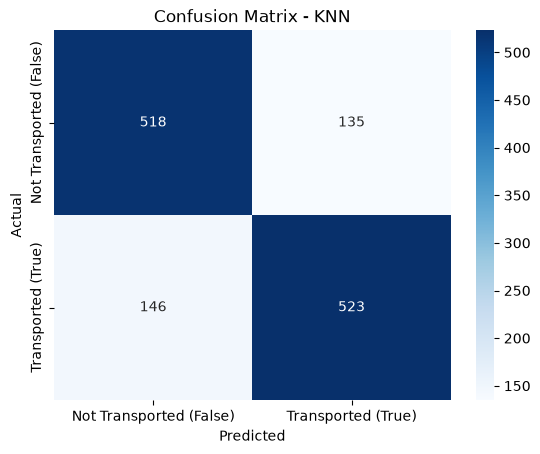

In [37]:
#lets do the heatmap to have a visualisation 

sns.heatmap(confusion_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Transported (False)", "Transported (True)"],   # names of the columns
            yticklabels=["Not Transported (False)", "Transported (True)"])   # names of the rows
plt.xlabel("Predicted by the model")   # columns = what the model guessed
plt.ylabel("Actual (real answer)")     # rows = what really happened

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - KNN")
plt.show()

In [39]:
# explanations
#The heatmap shows that the KNN model gets most predictions right (dark diagonal), and its mistakes are small and balanced between false alarms and missed cases.